# AACR Project GENIE AKT1 Cohort — questions A1–A5

Source: Jacob's *CBIO thoughts* deck, slides 9–11. Data: `brca_akt1_genie_2019` from genie.cbioportal.org (REST download).
428 breast cancer patients, one sample each, from 6 centres; curated treatment exposure flags (aromatase inhibitor, CDK4/6 inhibitor,
fulvestrant, chemotherapy, …), duration of CDK4/6 and fulvestrant treatment with censoring status, and OS from initial diagnosis.

**Design caveats that shape every answer here**
- This is a **case-control cohort built around AKT1 mutations** (126 AKT1-mutant vs 302 wild-type, almost all ER+). Gene frequencies are not population frequencies and AKT1 effects are the cohort's design variable.
- Treatment flags are "ever received" (any line, adjuvant or metastatic); there are no regimen start dates for aromatase inhibitors, so "OS from AI start" cannot be computed. The timeline gives the day of metastatic diagnosis and the day the sequenced specimen was taken.
- Primary endpoint used: **OS from metastatic diagnosis**, left-truncated at specimen collection for the Cox HR. OS from initial diagnosis is shown where it replicates a cBioPortal figure.
- 25% of samples come from panels whose gene lists are not in the GENIE BPC panel files (MDA, GRCC); those samples are assumed tested for every gene.

In [1]:
import sys, re, ast, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "genie_akt1"
F = []

P = cb.Portal("brca_akt1_genie_2019")
log = pd.read_csv(cb.DATA / "genie_portal" / "download_log.csv")
display(log[log.study_id == "brca_akt1_genie_2019"])

,study_id,file,rows,md5
0,brca_akt1_genie_2019,clinical_attributes.tsv,70,fb54e49038be0bc66b0f5409d90fda21
1,brca_akt1_genie_2019,data_clinical_patient.tsv,428,72118df4db64d7b7ab18f16369da98b5
2,brca_akt1_genie_2019,data_clinical_sample.tsv,428,4243b86e4fcf89d17d38026b1002eac5
3,brca_akt1_genie_2019,data_timeline.tsv,2045,ad90b0a91ca9b55d75f12a2c3fd655a2
4,brca_akt1_genie_2019,data_cna.tsv,145122,36a79fe4750e5f519740a3f037c3f304
5,brca_akt1_genie_2019,data_mutations.tsv,1929,782b68bafe75e6947d2d0d37276b37d6
6,brca_akt1_genie_2019,data_sv.tsv,39,eca63b056d814ac7bc14bae5d7e9ece9
7,brca_akt1_genie_2019,gene_panel_per_sample.tsv,428,db03754cc766c034f4a75b1989729f2b


## Cohort, endpoints and alteration matrix

patients 428; with metastatic-dx day 397; with specimen day 354; OS from met dx <= 0 (dropped from met-dx analyses): 0


,step,n,dropped
0,Patients in study,428,0
1,With OS from initial diagnosis,428,0
2,With OS from metastatic diagnosis,397,31
3,Aromatase-inhibitor treated,370,27
4,AI + CDK4/6 inhibitor treated,123,247


AI treated,False,True,All
hr_status,,,
ER+ & PR+,34,295,329
ER+ & PR-,10,49,59
ER-,11,12,23
unknown,3,14,17
All,58,370,428


AKT1 mutant,False,True,All
CENTER,,,
DFCI,45,23,68
GRCC,12,6,18
MDA,58,29,87
MSK,161,62,223
UHN,8,2,10
VICC,18,4,22
All,302,126,428


alteration matrix: 428 patients x 880 genes; samples with unknown panel: 105
median OS from met dx (all): 55.6 months; from initial dx: 56.6 months


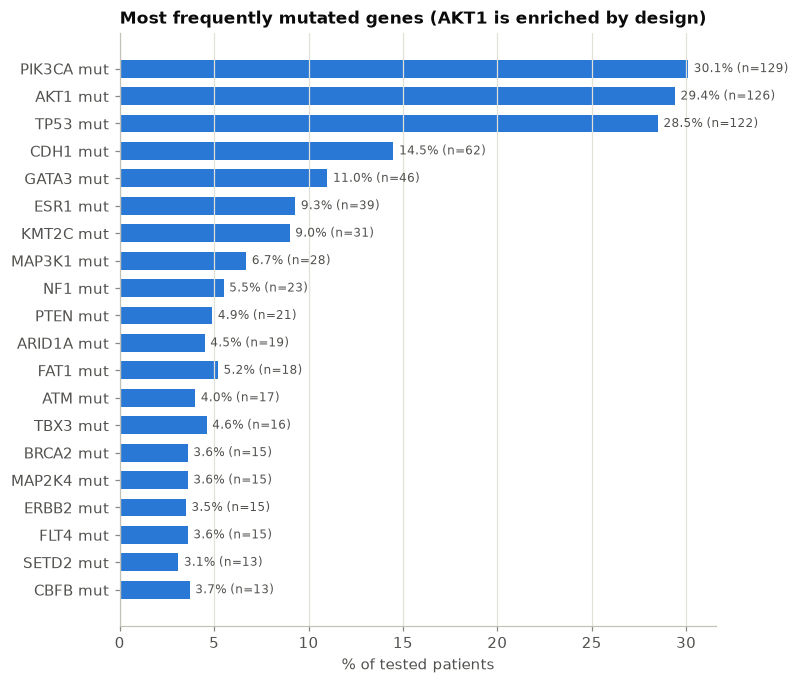

In [2]:
S = P.survival()                       # time = OS months from initial diagnosis
tl = pd.read_csv(P.dir / "data_timeline.tsv", sep="\t")
tl["attr"] = tl.attributes.apply(lambda s: {d["key"]: d["value"] for d in ast.literal_eval(s)} if isinstance(s, str) else {})
met_day = tl[(tl.eventType == "STATUS") & (tl.attr.apply(lambda a: a.get("STATUS") == "Metastatic Diagnosis"))].groupby("patientId").startNumberOfDaysSinceDiagnosis.min()
spec_day = tl[tl.eventType == "SPECIMEN"].groupby("patientId").startNumberOfDaysSinceDiagnosis.min()
S["met_dx_mos"] = met_day.reindex(S.index) / 30.4375
S["specimen_mos"] = spec_day.reindex(S.index) / 30.4375
S["time_met"] = (S.time - S.met_dx_mos)
S["entry"] = S.specimen_mos                                  # left truncation, OS from initial dx
S["entry_met"] = (S.specimen_mos - S.met_dx_mos).clip(lower=0)  # left truncation, OS from metastatic dx
sm = P.samples
S["age_met"] = pd.to_numeric(sm.AGE_AT_MET_DIAGNOSIS.reindex(S.index), errors="coerce")
S["hr_status"] = S.HORMONE_RECEPTOR_STATUS
S["er_pos"] = S.hr_status.astype(str).str.startswith("ER+")
S["ai"] = S.AROMATASE_INHIBITOR_YN.eq("Yes")
S["cdk"] = S.CDK46_INHIBITOR_YN.eq("Yes")
S["fulv"] = S.FULVESTRANT_YN.eq("Yes")
S["akt1"] = sm.AKT_MUTATION_STATUS.reindex(S.index).eq("Mutant")
bad = S.time_met <= 0
print(f"patients {len(S)}; with metastatic-dx day {S.met_dx_mos.notna().sum()}; with specimen day {S.specimen_mos.notna().sum()}; "
      f"OS from met dx <= 0 (dropped from met-dx analyses): {int(bad.sum())}")
S.loc[bad, "time_met"] = np.nan
display(cb.consort([("Patients in study", len(S)), ("With OS from initial diagnosis", int(S.time.notna().sum())),
                    ("With OS from metastatic diagnosis", int(S.time_met.notna().sum())), ("Aromatase-inhibitor treated", int(S.ai.sum())),
                    ("AI + CDK4/6 inhibitor treated", int((S.ai & S.cdk).sum()))]))
display(pd.crosstab(S.hr_status.fillna("unknown"), S.ai, margins=True).rename_axis(columns="AI treated"))
display(pd.crosstab(S.CENTER, S.akt1, margins=True).rename_axis(columns="AKT1 mutant"))
A = P.alterations()
print(f"alteration matrix: {len(A.patients)} patients x {len(A.genes)} genes; samples with unknown panel: {A.n_unknown_panel}")
freq = A.frequency(kinds=("mut", "amp", "homdel", "fus"))
ax = cb.bar_freq(freq[freq.kind == "mut"], top=20, title="Most frequently mutated genes (AKT1 is enriched by design)")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")
print("median OS from met dx (all):", cb.km_table(S.assign(g="all"), "g", time="time_met").median_months[0], "months;",
      "from initial dx:", cb.km_table(S.assign(g="all"), "g").median_months[0], "months")

## A2 (replicate) — Patients who received aromatase therapy lived longer than those who did not
Slide 10 (cBioPortal: OS from initial diagnosis, AI-treated vs not). Then the same comparison from metastatic diagnosis, within ER+ patients, and left-truncated. "Ever received an AI" is a survivor-dependent exposure, so the naive curves overstate any benefit.

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_naive
0,no AI,58,34,31.4,0.84,0.543,0.138,7.25e-10,0.323
1,AI treated,370,157,61.4,0.955,0.846,0.51,7.25e-10,0.323


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,no AI,56,34,31.4,0.833,0.528,0.134,5.64e-10
1,AI treated,341,149,59.1,0.954,0.845,0.498,5.64e-10


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,no AI,43,25,33.8,0.865,0.547,0.126,1.68e-07
1,AI treated,317,138,58.5,0.96,0.856,0.488,1.68e-07


,model,HR,HR_lo,HR_hi,p_cox,n_cox
0,"naive, OS from initial dx, all",0.323,0.221,0.472,4.87e-09,428
1,"OS from met dx, all",0.319,0.218,0.467,4.03e-09,397
2,"OS from met dx, ER+ only",0.332,0.215,0.513,6.35e-07,360
3,"OS from met dx, ER+, left-truncated at specime...",0.33,0.203,0.537,8.16e-06,309


[A2] replicated, but exposure is survivor-dependent: From initial dx: AI-treated n=370 median 61.4 vs 31.4 mo, p=7.3e-10, HR 0.32. From metastatic dx in ER+ patients: median 58.5 vs 33.8 mo, p=1.7e-07; left-truncated, age/HER2-adjusted HR 0.33 (p=8.2e-06). The untreated group is small (n=58) and enriched for ER− disease.


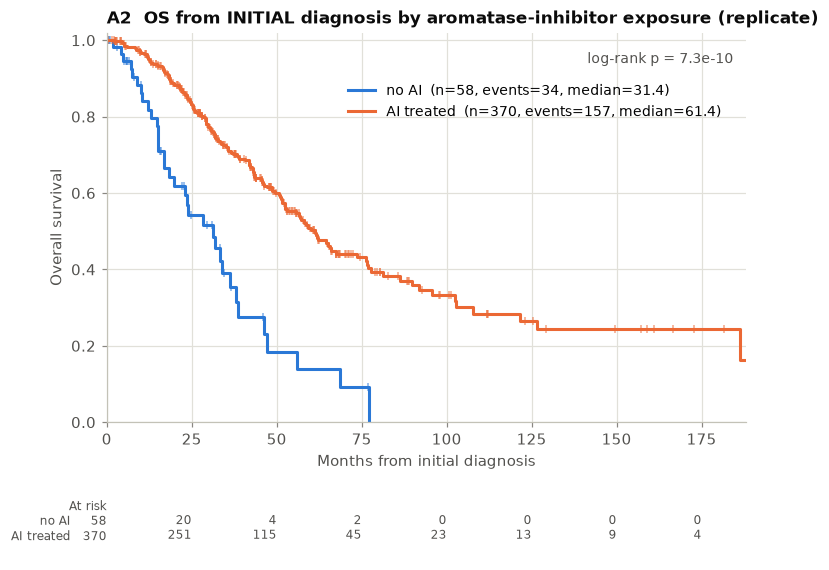

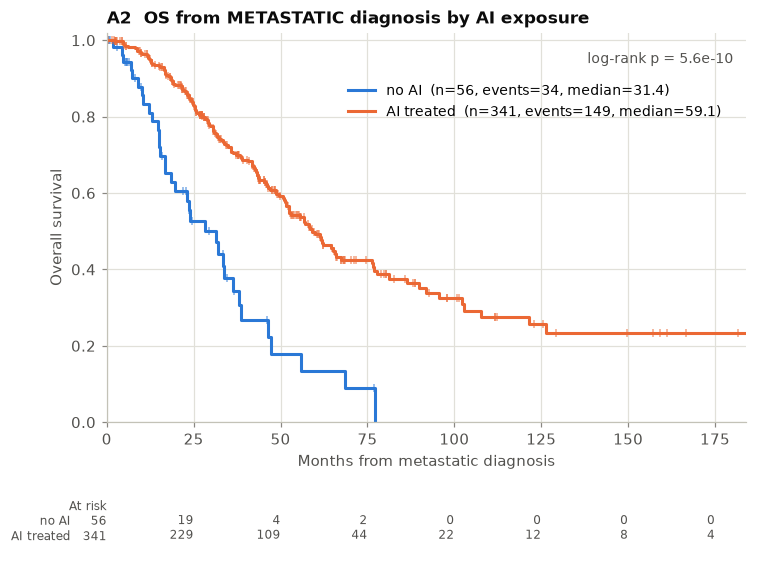

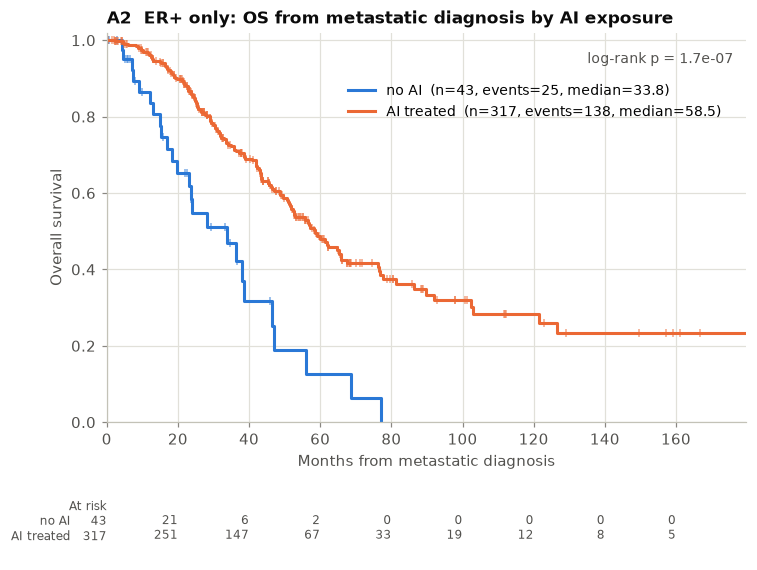

In [3]:
S["ai_grp"] = np.where(S.ai, "AI treated", "no AI")
order = ["no AI", "AI treated"]
ax, t2 = cb.km_plot(S, "ai_grp", order=order, title="A2  OS from INITIAL diagnosis by aromatase-inhibitor exposure (replicate)", xlabel="Months from initial diagnosis")
h2 = cb.hr(S, "ai"); t2["HR_naive"] = h2["HR"]
cb.save(DS, "A2", table=t2, fig=ax.figure, slug="replicate_from_initial_dx")
display(t2)
ax, t2b = cb.km_plot(S, "ai_grp", time="time_met", order=order, title="A2  OS from METASTATIC diagnosis by AI exposure", xlabel="Months from metastatic diagnosis")
cb.save(DS, "A2", table=t2b, fig=ax.figure, slug="from_met_dx")
display(t2b)
er = S[S.er_pos]
ax, t2c = cb.km_plot(er, "ai_grp", time="time_met", order=order, title="A2  ER+ only: OS from metastatic diagnosis by AI exposure", xlabel="Months from metastatic diagnosis")
cb.save(DS, "A2", table=t2c, fig=ax.figure, slug="er_pos_from_met_dx")
display(t2c)
models = pd.DataFrame([
    dict(model="naive, OS from initial dx, all", **cb.hr(S, "ai")),
    dict(model="OS from met dx, all", **cb.hr(S, "ai", time="time_met")),
    dict(model="OS from met dx, ER+ only", **cb.hr(er, "ai", time="time_met")),
    dict(model="OS from met dx, ER+, left-truncated at specimen, + age + HER2", **cb.hr(er, "ai", time="time_met", entry="entry_met", adjust=["age_met", "HER2_STATUSALL"])),
])
cb.save(DS, "A2", table=models, slug="cox_models")
display(models)
cb.finding("A2", "replicated, but exposure is survivor-dependent",
           f"From initial dx: AI-treated n={t2.n[1]} median {t2.median_months[1]} vs {t2.median_months[0]} mo, p={cb.fmt_p(t2.p_logrank[0])}, HR {h2['HR']:.2f}. "
           f"From metastatic dx in ER+ patients: median {t2c.median_months[1]} vs {t2c.median_months[0]} mo, p={cb.fmt_p(t2c.p_logrank[0])}; "
           f"left-truncated, age/HER2-adjusted HR {models.HR.iloc[-1]:.2f} (p={cb.fmt_p(models.p_cox.iloc[-1])}). The untreated group is small (n={t2.n[0]}) and enriched for ER− disease.", F)

## A1 / A3 — In AI-treated patients, which mutations are associated with worse OS? PIK3CA first, then every gene
Within AI-treated patients: OS from metastatic diagnosis, each gene feature (mutation / amplification / deep deletion) with ≥ 10 carriers and non-carriers; log-rank, left-truncated Cox HR, BH FDR. AKT1 is the cohort's design variable and is reported but should not be over-read.

,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,TP53 mut,TP53,mut,88,253,53,96,33.4,66,6.14e-09,2.46,1.72,3.5,6.78e-07,303,1.96e-07
1,NBN amp,NBN,amp,12,220,7,80,29.1,76.3,0.014,2.74,1.19,6.33,0.0183,211,0.224
2,CCND1 amp,CCND1,amp,60,190,29,67,48.8,76.9,0.0547,1.54,0.967,2.45,0.0687,222,0.44
3,NOTCH2 mut,NOTCH2,mut,10,322,0,144,inf,59.1,0.0554,1.21e-07,0,inf,0.993,294,0.44
4,MTOR mut,MTOR,mut,10,322,1,143,inf,59.1,0.0688,0.189,0.0264,1.36,0.0978,294,0.44
5,MDM4 amp,MDM4,amp,14,236,7,89,35.8,66,0.0845,1.9,0.823,4.37,0.133,222,0.451
6,MAP3K1 mut,MAP3K1,mut,24,308,7,137,inf,58.1,0.11,0.546,0.254,1.18,0.122,294,0.501
7,FGF3 amp,FGF3,amp,39,151,21,52,48.8,76.3,0.148,1.48,0.857,2.56,0.159,162,0.515
8,FGF4 amp,FGF4,amp,39,151,21,52,48.8,76.3,0.148,1.48,0.857,2.56,0.159,162,0.515
9,FGFR1 amp,FGFR1,amp,35,215,15,81,48.8,66,0.161,1.52,0.854,2.69,0.156,222,0.515


[A1] signal: 1 of 32 features at FDR<0.1: TP53 mut (n=88) HR 2.46 q=2e-07


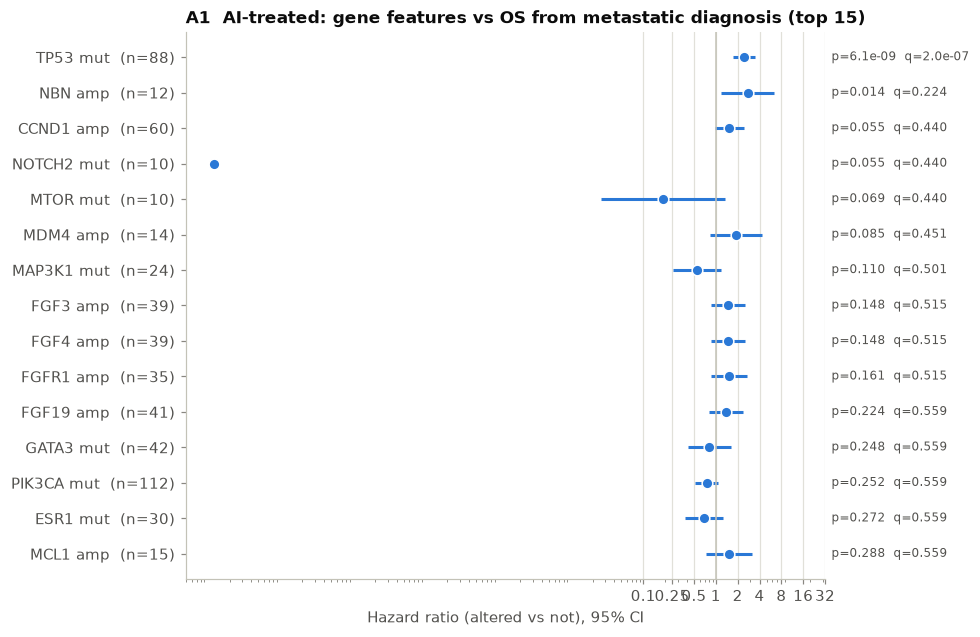

In [4]:
ai = S[S.ai]
scr = cb.gene_screen(ai, A, kinds=("mut", "amp", "homdel"), min_n=10, time="time_met", event="event", entry="entry_met")
ax = cb.forest_plot(scr, top=15, title="A1  AI-treated: gene features vs OS from metastatic diagnosis (top 15)")
cb.save(DS, "A1", table=scr, fig=ax.figure, slug="gene_screen_in_ai_treated")
display(scr.head(15))
hits = scr[scr.q_bh < 0.1]
cb.finding("A1", "signal" if len(hits) else "no signal",
           (f"{len(hits)} of {len(scr)} features at FDR<0.1: " + "; ".join(f"{r.feature} (n={r.n_alt}) HR {r.HR:.2f} q={r.q_bh:.2g}" for r in hits.itertuples()))
           if len(hits) else f"none of {len(scr)} features passes FDR<0.1 (best {scr.feature[0]} HR {scr.HR[0]:.2f} p={cb.fmt_p(scr.p_logrank[0])})", F)

n  events  median_months  surv_1y  surv_2y  surv_5y  p_logrank    HR  HR_lo  HR_hi    p_cox
gene   group                                                                                                    
PIK3CA PIK3CA wt   229      99           56.6    0.959    0.835    0.489      0.252   NaN    NaN    NaN      NaN
       PIK3CA mut  112      50           61.4    0.944    0.866    0.521      0.252 0.749  0.524   1.07    0.112
AKT1   AKT1 wt     242     112           58.5    0.966    0.859    0.486      0.407   NaN    NaN    NaN      NaN
       AKT1 mut     99      37           64.6    0.926    0.812    0.541      0.407 0.953  0.632   1.44    0.819
TP53   TP53 wt     253      96             66    0.988    0.912    0.584   6.14e-09   NaN    NaN    NaN      NaN
       TP53 mut     88      53           33.4    0.858    0.652    0.245   6.14e-09  2.46   1.72    3.5 6.78e-07
ESR1   ESR1 wt     302     130           58.5    0.951    0.839    0.488      0.272   NaN    NaN    NaN      NaN
       ESR1 mut     30      14           67.4    0.967    0.931    0.631      0.272 0.689  0.377   1.26    0.225
GATA3  GATA3 wt    290     134           58.5     0.95    0.839     0.49      0.248   NaN    NaN    NaN      NaN
       GATA3 mut    42      10           67.4    0.974    0.918    0.644      0.248 0.816  0.413   1.61     0.56
CDH1   CDH1 wt     294     129             60    0.961    0.848    0.501      0.849   NaN    NaN    NaN      NaN
       CDH1 mut     47      20           59.1    0.906    0.829     0.48      0.849  1.08  0.662   1.75    0.767
MAP3K1 MAP3K1 wt   308     137           58.1    0.953     0.85    0.481       0.11   NaN    NaN    NaN      NaN
       MAP3K1 mut   24       7            inf    0.955    0.808    0.808       0.11 0.546  0.254   1.18    0.122

[A3] no difference: AI-treated, PIK3CA-mut n=112 median OS from met dx 61.4 vs wt 56.6 mo, p=0.252, HR (LT) 0.75 [0.52-1.07]. AKT1 HR 0.95 (p=0.407); TP53 HR 2.46 (p=6.1e-09); ESR1 HR 0.69 (p=0.272).


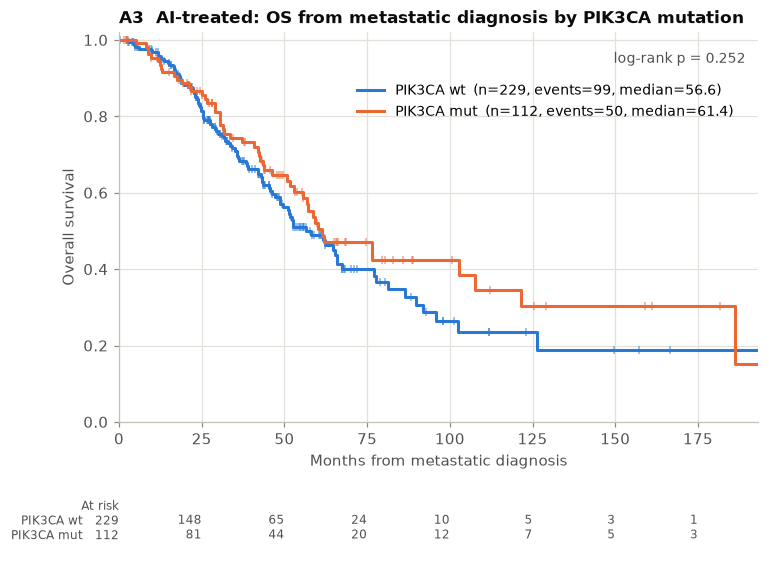

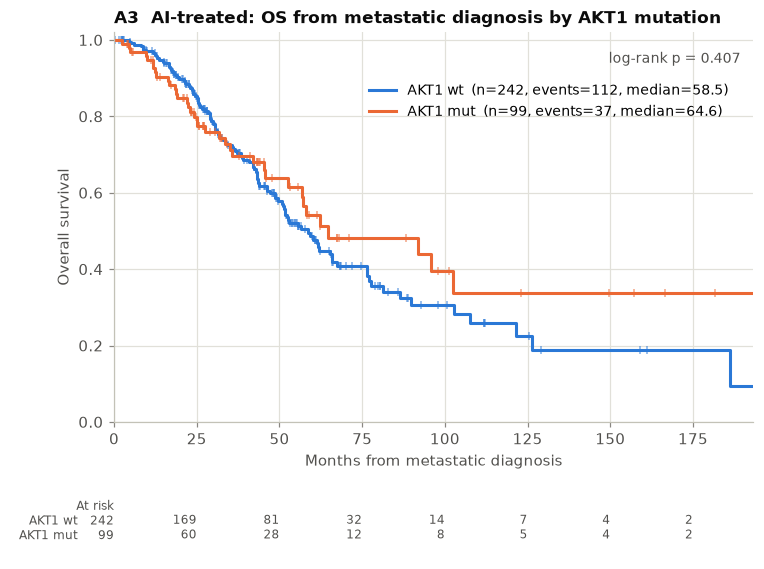

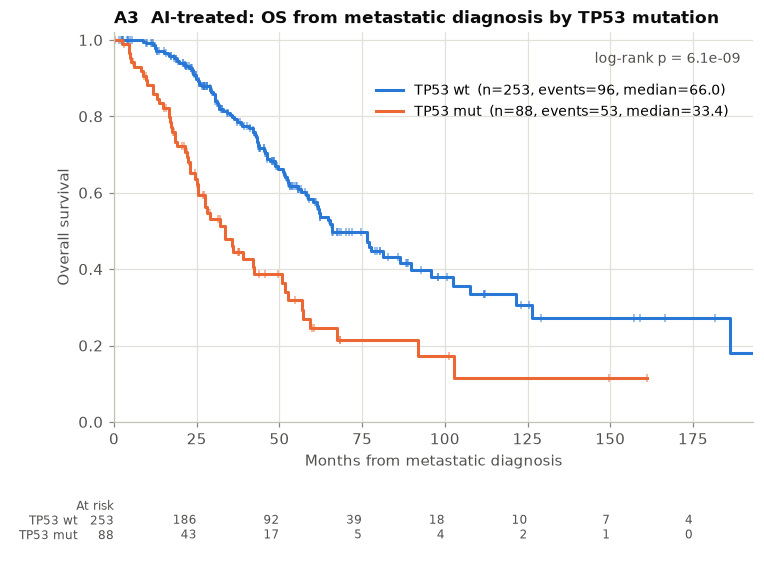

In [5]:
rows = []
for g in ["PIK3CA", "AKT1", "TP53", "ESR1", "GATA3", "CDH1", "MAP3K1"]:
    d, t = cb.compare(ai, A.status(g), labels=(f"{g} wt", f"{g} mut"), time="time_met", event="event", entry="entry_met")
    rows.append(t.assign(gene=g))
    if g in ("PIK3CA", "AKT1", "TP53"):
        ax, _ = cb.km_plot(d, "group", time="time_met", order=[f"{g} wt", f"{g} mut"], title=f"A3  AI-treated: OS from metastatic diagnosis by {g} mutation", xlabel="Months from metastatic diagnosis")
        cb.save(DS, "A3", table=t, fig=ax.figure, slug=f"ai_by_{g}")
a3 = pd.concat(rows).set_index(["gene", "group"])
cb.save(DS, "A3", table=a3.reset_index(), slug="key_genes")
display(a3)
pk = a3.loc["PIK3CA"]
cb.finding("A3", "no difference" if pk.p_logrank.iloc[0] > 0.05 else "signal",
           f"AI-treated, PIK3CA-mut n={pk.n.iloc[1]} median OS from met dx {pk.median_months.iloc[1]} vs wt {pk.median_months.iloc[0]} mo, p={cb.fmt_p(pk.p_logrank.iloc[0])}, HR (LT) {pk.HR.iloc[1]:.2f} [{pk.HR_lo.iloc[1]:.2f}-{pk.HR_hi.iloc[1]:.2f}]. "
           + "; ".join(f"{g} HR {a3.loc[g].HR.iloc[1]:.2f} (p={cb.fmt_p(a3.loc[g].p_logrank.iloc[0])})" for g in ["AKT1", "TP53", "ESR1"]) + ".", F)

## A4 — AI-treated patients with co-occurring PIK3CA + AKT1 + TP53 mutations
Mutually exclusive profiles over the three genes (restricted to patients tested for all three), plus every pairwise combination.

profile
none of the three    114
PIK3CA                87
AKT1                  70
TP53                  37
AKT1+TP53             29
PIK3CA+TP53           28
PIK3CA+AKT1            3
other combination      2
Name: AI-treated patients, dtype: int64

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,none of the three,102,43,65.2,1,0.922,0.531,2.31e-07
1,PIK3CA,80,34,76.3,0.974,0.904,0.582,2.31e-07
2,AKT1,68,19,95.7,0.984,0.901,0.659,2.31e-07
3,TP53,33,21,27.5,0.935,0.642,0.202,2.31e-07
4,PIK3CA+TP53,27,14,50.7,0.852,0.737,0.344,2.31e-07
5,AKT1+TP53,26,16,27.6,0.764,0.537,0.29,2.31e-07
6,PIK3CA+AKT1,3,0,inf,1,1,1,2.31e-07
7,other combination,2,2,56.8,1,1,0,2.31e-07


,combination,n,events,median_with,median_rest,p_logrank,HR,HR_lo,HR_hi
0,PIK3CA+TP53,29,16,50.7,61.6,0.0942,1.38,0.793,2.4
1,AKT1+TP53,28,18,33.4,61.9,0.00119,2.06,1.2,3.53
2,PIK3CA+AKT1,5,2,57,60,0.171,0.385,0.094,1.58
3,PIK3CA+AKT1+TP53,2,2,56.8,60,0.535,1.58,0.388,6.39


[A4] signal: PIK3CA+TP53 n=29 median 50.7 vs 61.6 mo, HR 1.38 (p=0.094); AKT1+TP53 n=28 median 33.4 vs 61.9 mo, HR 2.06 (p=0.001); PIK3CA+AKT1 n=5 median 57.0 vs 60.0 mo, HR 0.39 (p=0.171); PIK3CA+AKT1+TP53 n=2 median 56.8 vs 60.0 mo, HR 1.58 (p=0.535)


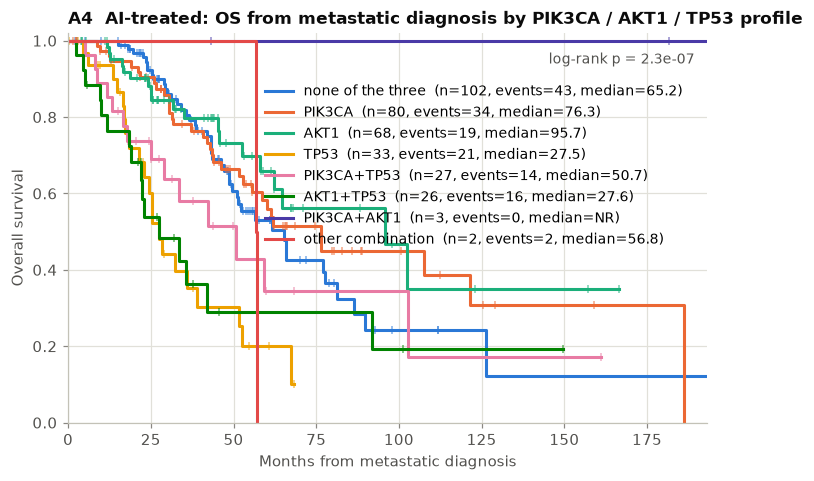

In [6]:
prof = A.combo_groups(["PIK3CA", "AKT1", "TP53"], min_n=5, wt_label="none of the three")
d4 = ai.join(prof, how="inner")
display(d4.profile.value_counts().rename("AI-treated patients"))
order4 = [g for g in ["none of the three", "PIK3CA", "AKT1", "TP53", "PIK3CA+TP53", "AKT1+TP53", "PIK3CA+AKT1", "PIK3CA+AKT1+TP53", "other combination"] if g in set(d4.profile)]
ax, t4 = cb.km_plot(d4, "profile", time="time_met", order=order4, title="A4  AI-treated: OS from metastatic diagnosis by PIK3CA / AKT1 / TP53 profile", xlabel="Months from metastatic diagnosis", risk_table=False)
cb.save(DS, "A4", table=t4, fig=ax.figure, slug="profiles")
display(t4)
# pairwise: each combination vs the rest of AI-treated patients
rows = []
for combo in [("PIK3CA", "TP53"), ("AKT1", "TP53"), ("PIK3CA", "AKT1"), ("PIK3CA", "AKT1", "TP53")]:
    st = pd.concat([A.status(g).rename(g) for g in combo], axis=1, join="inner").all(axis=1)
    d, t = cb.compare(ai, st, labels=("rest", "+".join(combo)), time="time_met", event="event", entry="entry_met")
    rows.append(dict(combination="+".join(combo), n=t.n[1], events=t.events[1], median_with=t.median_months[1], median_rest=t.median_months[0],
                     p_logrank=t.p_logrank[0], HR=t.attrs["HR"], HR_lo=t.attrs["HR_lo"], HR_hi=t.attrs["HR_hi"]))
pair = pd.DataFrame(rows)
cb.save(DS, "A4", table=pair, slug="pairwise_combinations")
display(pair)
cb.finding("A4", "signal" if (pair.p_logrank < 0.05).any() else "no signal / underpowered",
           "; ".join(f"{r.combination} n={r.n} median {r.median_with} vs {r.median_rest} mo, HR {r.HR:.2f} (p={cb.fmt_p(r.p_logrank)})" for r in pair.itertuples()), F)

## A5 — 126 patients received CDK4/6 inhibitors, 123 with an AI: survival of the combination, then which mutations predict poorer outcomes
Two endpoints: OS from metastatic diagnosis, and **duration of CDK4/6 treatment** (`CDK_4_6_DOT`, event = discontinuation), which is the closest thing to a response measure in this dataset. Groups of ≥ 8 given n = 123. Reference: PMID 39754979.

AI + CDK4/6: n=123; AKT1-mutant 38; deaths 29; CDK4/6 discontinuations 116


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,OS from met dx,113,29,95.7,0.962,0.909,0.701,NaN
0,time on CDK4/6i,123,116,5.6,0.263,0.018,0,NaN


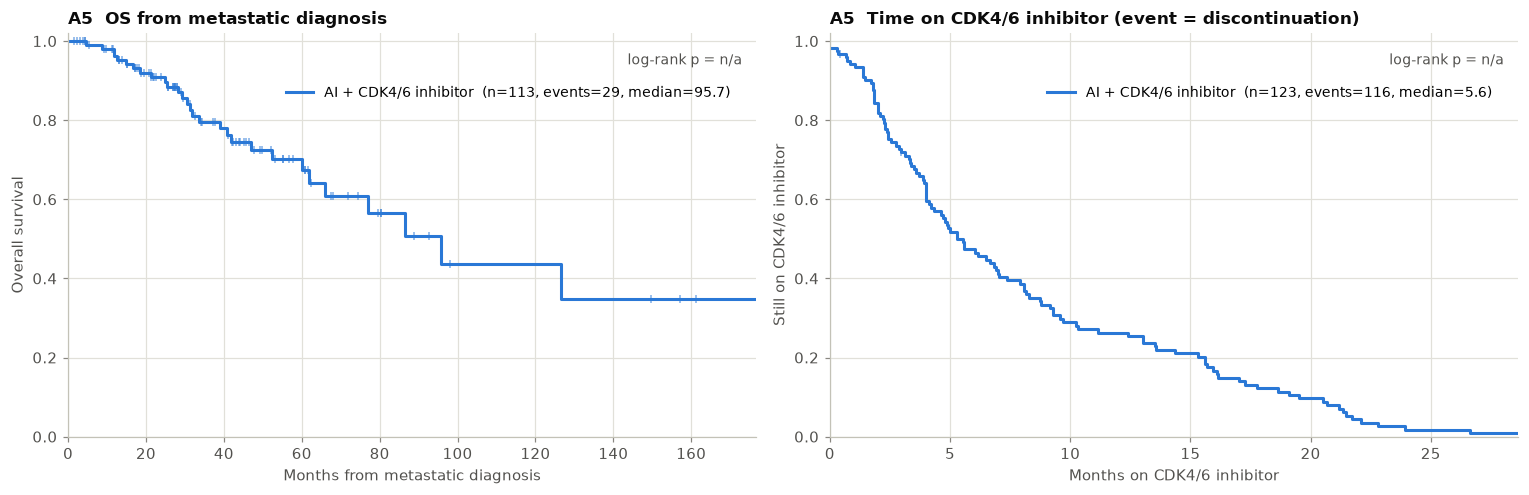

In [7]:
ac = S[S.ai & S.cdk].copy()
ac["cdk_time"] = pd.to_numeric(ac.CDK_4_6_DOT, errors="coerce")
ac["cdk_event"] = ac.CDK_4_6_SENSORING_STATUS.eq("event").astype(int)
print(f"AI + CDK4/6: n={len(ac)}; AKT1-mutant {int(ac.akt1.sum())}; deaths {int(ac.event.sum())}; CDK4/6 discontinuations {int(ac.cdk_event.sum())}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
cb.km_plot(ac.assign(g="AI + CDK4/6 inhibitor"), "g", time="time_met", ax=axes[0], title="A5  OS from metastatic diagnosis", xlabel="Months from metastatic diagnosis", risk_table=False)
cb.km_plot(ac.assign(g="AI + CDK4/6 inhibitor"), "g", time="cdk_time", event="cdk_event", ax=axes[1], title="A5  Time on CDK4/6 inhibitor (event = discontinuation)", xlabel="Months on CDK4/6 inhibitor", risk_table=False)
axes[1].set_ylabel("Still on CDK4/6 inhibitor")
fig.tight_layout()
t5 = pd.concat([cb.km_table(ac.assign(g="OS from met dx"), "g", time="time_met"), cb.km_table(ac.assign(g="time on CDK4/6i"), "g", time="cdk_time", event="cdk_event")])
cb.save(DS, "A5", table=t5, fig=fig, slug="combination_curves")
display(t5)

,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,TP53 mut,TP53,mut,25,88,10,19,38.9,95.7,0.0108,2.1,0.927,4.75,0.0754,93,0.194
1,AKT1 mut,AKT1,mut,36,77,5,24,inf,76.9,0.0931,0.561,0.194,1.62,0.285,93,0.553
2,FGFR1 amp,FGFR1,amp,15,89,6,21,60,95.7,0.114,1.9,0.753,4.8,0.174,86,0.553
3,CCND1 amp,CCND1,amp,27,77,9,18,66,126,0.168,1.71,0.749,3.9,0.203,86,0.553
4,FGF4 amp,FGF4,amp,19,58,7,12,66,86.4,0.208,1.74,0.668,4.51,0.258,59,0.553
5,FGF3 amp,FGF3,amp,19,58,7,12,66,86.4,0.208,1.74,0.668,4.51,0.258,59,0.553
6,CDH1 mut,CDH1,mut,20,93,8,21,76.9,95.7,0.239,1.41,0.613,3.26,0.417,93,0.553
7,PIK3CA mut,PIK3CA,mut,30,83,10,19,61.9,95.7,0.247,1.42,0.654,3.08,0.376,93,0.553
8,KMT2C mut,KMT2C,mut,14,70,5,16,47.1,86.4,0.301,2.16,0.776,6.03,0.14,64,0.553
9,FGF19 amp,FGF19,amp,21,56,7,12,66,86.4,0.331,1.48,0.567,3.85,0.424,59,0.553


,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,NF1 mut,NF1,mut,12,110,11,104,3.7,5.6,0.0578,1.82,0.969,3.42,0.0626,122,0.537
1,FGFR1 amp,FGFR1,amp,17,97,17,93,3.9,6.2,0.0735,1.62,0.955,2.74,0.0738,114,0.537
2,NOTCH2 mut,NOTCH2,mut,8,114,7,108,3.6,5.6,0.0768,2.01,0.922,4.37,0.0792,122,0.537
3,MAP3K1 mut,MAP3K1,mut,12,110,11,104,7.4,4.9,0.133,0.609,0.316,1.17,0.137,122,0.698
4,FGF3 amp,FGF3,amp,20,67,20,63,4,5.3,0.26,1.34,0.804,2.23,0.262,87,0.966
5,FGF4 amp,FGF4,amp,21,66,21,62,4,4.9,0.387,1.25,0.756,2.05,0.388,87,0.966
6,FGF19 amp,FGF19,amp,23,64,23,60,4,4.9,0.392,1.24,0.76,2.01,0.394,87,0.966
7,PAK1 amp,PAK1,amp,13,67,13,63,3.7,5.3,0.563,1.19,0.653,2.17,0.567,80,0.966
8,KMT2C mut,KMT2C,mut,14,80,14,73,4.3,4.9,0.603,1.17,0.655,2.08,0.599,94,0.966
9,AKT1 mut,AKT1,mut,38,85,34,82,5.6,5.3,0.604,0.901,0.602,1.35,0.61,123,0.966


[A5] no signal at FDR<0.1: n=123, median OS from met dx 95.7 mo, median time on CDK4/6i 5.6 mo. OS hits: none (best TP53 mut HR 2.10 p=0.011). Time-on-treatment hits: none (best NF1 mut HR 1.82 p=0.058).


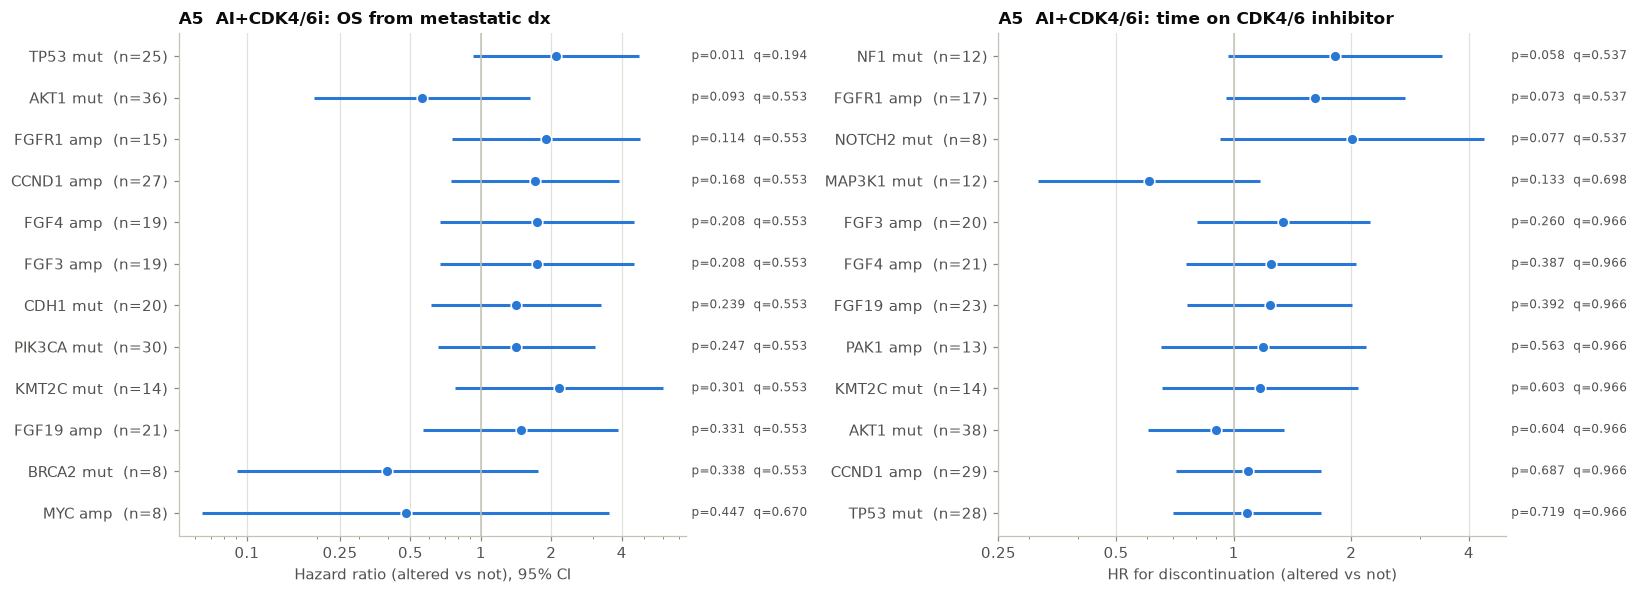

In [8]:
scr_os = cb.gene_screen(ac, A, kinds=("mut", "amp", "homdel"), min_n=8, time="time_met", event="event", entry="entry_met")
scr_dot = cb.gene_screen(ac, A, kinds=("mut", "amp", "homdel"), min_n=8, time="cdk_time", event="cdk_event")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cb.forest_plot(scr_os, top=12, title="A5  AI+CDK4/6i: OS from metastatic dx", ax=axes[0])
cb.forest_plot(scr_dot, top=12, title="A5  AI+CDK4/6i: time on CDK4/6 inhibitor", ax=axes[1]); axes[1].set_xlabel("HR for discontinuation (altered vs not)")
fig.tight_layout()
cb.save(DS, "A5", table=scr_os, fig=fig, slug="gene_screen_os")
cb.save(DS, "A5", table=scr_dot, slug="gene_screen_time_on_cdk46")
display(scr_os.head(10)); display(scr_dot.head(10))
h5 = scr_os[scr_os.q_bh < 0.1]; h5d = scr_dot[scr_dot.q_bh < 0.1]
cb.finding("A5", "signal" if (len(h5) or len(h5d)) else "no signal at FDR<0.1",
           f"n={len(ac)}, median OS from met dx {t5.median_months.iloc[0]} mo, median time on CDK4/6i {t5.median_months.iloc[1]} mo. OS hits: " +
           (", ".join(f"{r.feature} HR {r.HR:.2f} q={r.q_bh:.2g}" for r in h5.itertuples()) or f"none (best {scr_os.feature[0]} HR {scr_os.HR[0]:.2f} p={cb.fmt_p(scr_os.p_logrank[0])})") +
           ". Time-on-treatment hits: " + (", ".join(f"{r.feature} HR {r.HR:.2f} q={r.q_bh:.2g}" for r in h5d.itertuples()) or f"none (best {scr_dot.feature[0]} HR {scr_dot.HR[0]:.2f} p={cb.fmt_p(scr_dot.p_logrank[0])})") + ".", F)

## Summary of findings

In [9]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,A2,"replicated, but exposure is survivor-dependent","From initial dx: AI-treated n=370 median 61.4 vs 31.4 mo, p=7.3e-10, HR 0.32. From metastatic dx in ER+ patients: median 58.5 vs 33.8 mo, p=1.7e-07; left-truncated, age/HER2-adjusted HR 0.33 (p=8.2e-06). The untreated group is small (n=58) and enriched for ER− disease."
1,A1,signal,1 of 32 features at FDR<0.1: TP53 mut (n=88) HR 2.46 q=2e-07
2,A3,no difference,"AI-treated, PIK3CA-mut n=112 median OS from met dx 61.4 vs wt 56.6 mo, p=0.252, HR (LT) 0.75 [0.52-1.07]. AKT1 HR 0.95 (p=0.407); TP53 HR 2.46 (p=6.1e-09); ESR1 HR 0.69 (p=0.272)."
3,A4,signal,"PIK3CA+TP53 n=29 median 50.7 vs 61.6 mo, HR 1.38 (p=0.094); AKT1+TP53 n=28 median 33.4 vs 61.9 mo, HR 2.06 (p=0.001); PIK3CA+AKT1 n=5 median 57.0 vs 60.0 mo, HR 0.39 (p=0.171); PIK3CA+AKT1+TP53 n=2 median 56.8 vs 60.0 mo, HR 1.58 (p=0.535)"
4,A5,no signal at FDR<0.1,"n=123, median OS from met dx 95.7 mo, median time on CDK4/6i 5.6 mo. OS hits: none (best TP53 mut HR 2.10 p=0.011). Time-on-treatment hits: none (best NF1 mut HR 1.82 p=0.058)."
